# Adversarial Search: Solving Tic-Tac-Toe with Heuristic Alpha-Beta Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. __Heuristic Alpha-Beta Tree Search:__ Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Heuristic Alpha-Beta Tree Search

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Heuristic Alpha-Beta Tree Search

See AIMA page 156ff. 


## Heuristic Evaluation Function

In [3]:
import numpy as np

def eval_fun(state, player = 'x'):
    """heuristic for utility of state. Returns score for a node:
    1. For terminal states it returns the utility. 
    2. For non-terminal states, it calculates a weighted linear function using features of the state. 
    The features we look at are 2 in a row/col/diagonal where the 3rd square is empty. We assume that
    the more of these positions we have, the higher the chance of winning.
    We need to be careful that the utility of the heuristic stays between [-1,1]. 
    Note that the largest possible number of these positions is 2. I weigh the count by 0.4, 
    guaranteeing that is in the needed range.
    
    Function Returns: heuristic value, terminal?"""
    
    # terminal state?
    u = utility(state, player)
    if u is not None: return u, True
      
    score = 0
    board = np.array(state).reshape((3,3))
    diagonals = np.array([[board[i][i] for i in range(len(board))], 
                          [board[i][len(board)-i-1] for i in range(len(board))]])
    
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row ==' '): score += .4
            if sum(row == other(player)) == 2 and any(row ==' '): score -= .4
    
    return score, False

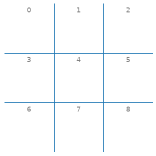

eval for x: (0, False)
eval for o: (0, False)


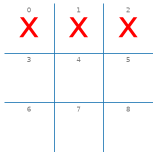

eval for x: (1, True)
eval for o: (-1, True)


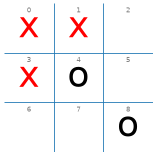

eval for x: (0.8, False)
eval for o: (-0.8, False)


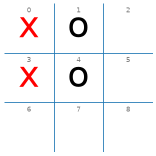

eval for x: (0.0, False)
eval for o: (0.0, False)


In [4]:
board = empty_board() 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[2] = 'x' 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[3] = 'x' 
board[4] = 'o'
board[8] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'x' 
board[4] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

**[Bài 4] Nhận xét `eval_fun`:**
- Trạng thái kết thúc trả về đúng utility (+1 / −1 / 0) kèm cờ `True`; trạng thái chưa kết thúc trả về ước lượng kèm `False`.
- Ước lượng là hàm tuyến tính có trọng số: mỗi hàng/cột/đường chéo có **2 quân của mình và ô thứ 3 trống** được +0,4,
  của đối thủ thì −0,4. Ví dụ bàn thứ 3: X có hai "hai quân hở" (hàng 0 và cột 0) nên +0,8.
- Hàm **đối xứng**: giá trị cho O luôn bằng âm giá trị cho X, phù hợp trò chơi tổng bằng 0.
- **Lưu ý: chú thích của hàm nói ước lượng luôn nằm trong [−1, 1] là chưa đúng.** Chú thích cho rằng mỗi bên có
  tối đa 2 đường "hai quân hở", nhưng có thể có 3. Kiểm tra toàn bộ 4.520 trạng thái chưa kết thúc có thể xảy ra:
  ước lượng đạt tới **±1,2** (ví dụ `x o x / o x x / _ o _` cho X được +1,2), và 100 trạng thái có |ước lượng| ≥ 1.
  Khi đó một thế **chưa kết thúc** có thể được chấm ngang hoặc cao hơn một chiến thắng thật (+1), nên ở điểm cắt
  agent có thể đánh giá một thế "nhiều đe dọa" ngang với thắng ngay. Muốn giữ đúng thang [−1, 1] cần giảm trọng số
  (ví dụ 0,3) hoặc chặn giá trị (clip) vào khoảng (−1, 1).

## Search with Cutoff

We add a cutoff to the Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning (see AIMA page 156ff). We use the heuristic evaluation function and the back-up the value using minimax search with alpha-beta pruning to determine the next move.

In [5]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, cutoff = None, player = 'x'):
    """start the search. cutoff = None is minimax search with alpha-beta pruning."""
    global DEBUG, COUNT
    COUNT = 0

    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    
    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}") 
    
    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    
    return v, move

In [6]:
# [Bài 4] Công cụ đo: chạy một lần tìm kiếm, ghi nước đi, giá trị, số nút và thời gian.
import time
import pandas as pd

def run_case(board, cutoff, player='x'):
    """Gọi alpha_beta_search (không in), trả số nút COUNT và thời gian (ms)."""
    global DEBUG
    old_debug, DEBUG = DEBUG, 0
    start = time.perf_counter()
    found = alpha_beta_search(board, cutoff, player)
    elapsed_ms = (time.perf_counter() - start) * 1000
    DEBUG = old_debug
    return {'move': found['move'], 'value': found['value'], 'nodes': COUNT, 'ms': elapsed_ms}

def exact_move_value(board, player, move):
    """Giá trị minimax chính xác (tìm tới trạng thái kết thúc) của nước `move`, theo góc nhìn `player`."""
    global DEBUG
    old_debug, DEBUG = DEBUG, 0
    value, _ = min_value_ab(result(board, player, move), player, -math.inf, math.inf, 1, None)
    DEBUG = old_debug
    return value

**[Bài 4] Tham số `cutoff` và các agent heuristic:**
- `cutoff` là độ sâu tối đa (tính từ gốc, gốc có độ sâu 0). Khi `depth >= cutoff` hoặc gặp trạng thái kết thúc,
  nút được đánh giá bằng `eval_fun` thay vì đi tiếp. `cutoff = None` là Alpha-Beta đầy đủ (tìm tới trạng thái kết thúc).
- Phần còn lại giống Alpha-Beta của Bài 3: `max_value_ab` (lượt người tìm) cập nhật α, `min_value_ab` (lượt đối thủ)
  cập nhật β, cắt tỉa khi `v ≥ β` hoặc `v ≤ α`.
- Ở ô thí nghiệm bên dưới, `heuristic2_player` / `heuristic4_player` là agent gọi `alpha_beta_search` với cutoff 2 / 4,
  `alpha_beta_player` là Alpha-Beta không cutoff.
- Ô **[Bài 4]** ngay trên định nghĩa hai hàm đo dùng chung: `run_case` (nước đi, giá trị, số nút `COUNT`, thời gian)
  và `exact_move_value` (giá trị minimax chính xác của một nước, dùng để đánh giá chất lượng quyết định).

## Some Tests

### x is about to win (play 8)

Board:


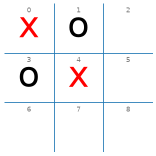


Number of nodes searched (cutoff = 2): 13


{'move': 8, 'value': 1}

CPU times: total: 0 ns
Wall time: 1.99 ms

Number of nodes searched (cutoff = 4): 47


{'move': 2, 'value': 1}

CPU times: total: 15.6 ms
Wall time: 2.99 ms

Number of nodes searched (cutoff = None): 61


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 4.01 ms


In [7]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))

print()
%time display(alpha_beta_search(board, 4))

print()
%time display(alpha_beta_search(board))

**[Bài 4] Nhận xét — x sắp thắng:** cutoff 2 chọn **8** (thắng ngay, 13 nút); cutoff 4 và không cutoff chọn **2**
(tạo hai đường đe dọa 2–4–6 và 0–4–8, X vẫn thắng ở nước sau; 47 và 61 nút). Cả ba đều có giá trị thật +1 nên đều tối ưu.
Alpha-Beta chỉ so giá trị +1 với +1 nên không ưu tiên thắng nhanh hơn. Cutoff 2 chọn thắng ngay vì trong phạm vi
độ sâu 2, chỉ nước 8 dẫn tới trạng thái kết thúc có giá trị chắc chắn +1; nước 2 mới chỉ được ước lượng (nhỏ hơn 1).

### o is about to win

Board:


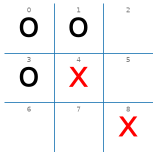


Number of nodes searched (cutoff = 2): 11


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 1.01 ms

Number of nodes searched (cutoff = None): 15


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 2 ms


In [8]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board))

**[Bài 4] Nhận xét — o sắp thắng:** O có hai đường đe dọa (ô 2 và ô 6) nên X thua dù đi đâu. Cutoff 2 (11 nút) và
không cutoff (15 nút) cùng chọn **2** với giá trị −1. Thế cờ đã gần cuối nên cây rất nhỏ: cutoff 2 nhìn tới nước thắng
của O và cho giá trị chính xác, tìm đầy đủ chỉ tốn thêm 4 nút.

### x can draw if it chooses 7

Board:


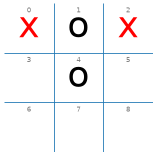


Number of nodes searched (cutoff = 2): 21


{'move': 7, 'value': -0.4}

CPU times: total: 0 ns
Wall time: 3.01 ms

Number of nodes searched (cutoff = 4): 81


{'move': 7, 'value': 0}

CPU times: total: 0 ns
Wall time: 6 ms

Number of nodes searched (cutoff = None): 101


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 8 ms


In [9]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

**[Bài 4] Nhận xét — x hòa được nếu đi 7:** cả ba cấu hình đều chọn **7** (nước duy nhất chặn đường 1–4–7 của O).
Cutoff 2 (21 nút) ước lượng **−0,4** trong khi giá trị thật là **0** (hòa): ở độ sâu 2 ván chưa kết thúc nên giá trị
chỉ là ước lượng từ số đường "hai quân hở", bi quan hơn thực tế, nhưng vẫn xếp nước 7 cao nhất. Cutoff 4 (81 nút) và không cutoff (101 nút)
cho đúng giá trị 0.

### Empty board: Only a draw an be guaranteed

Board:


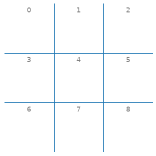


Number of nodes searched (cutoff = 2): 26


{'move': 0, 'value': 0}

CPU times: total: 0 ns
Wall time: 2.6 ms

Number of nodes searched (cutoff = 4): 541


{'move': 4, 'value': 0.0}

CPU times: total: 46.9 ms
Wall time: 33.6 ms

Number of nodes searched (cutoff = None): 18297


{'move': 0, 'value': 0}

CPU times: total: 781 ms
Wall time: 788 ms


In [10]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

**[Bài 4] Nhận xét — bàn trống:** đây là trường hợp chênh lệch chi phí lớn nhất: **26** nút (cutoff 2), **541** nút
(cutoff 4) và **18.297** nút (không cutoff), tức tìm đầy đủ tốn gấp khoảng 700 lần cutoff 2 (xem thời gian ở output trên).
Cả ba đều cho giá trị 0 (chỉ đảm bảo được hòa): cutoff 2 và không cutoff chọn góc **0**, cutoff 4 chọn ô giữa **4**;
cả hai nước đều giữ được hòa.

### A bad situation

Board:


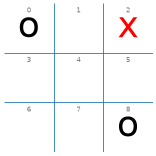


Number of nodes searched (cutoff = 2): 29


{'move': 4, 'value': -0.8}

CPU times: total: 0 ns
Wall time: 3.01 ms

Number of nodes searched (cutoff = 4): 148


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 9 ms

Number of nodes searched (cutoff = None): 238


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 12 ms


In [11]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

**[Bài 4] Nhận xét — thế xấu:** với tìm kiếm đầy đủ, X thua dù đi đâu (giá trị −1; cả cutoff 4 và không cutoff chọn
**1**, 148 và 238 nút). Cutoff 2 (29 nút) chọn **4** với ước lượng **−0,8**: nó chưa nhìn thấy đường thắng chắc chắn của O
nên đánh giá tình thế ít tệ hơn thực tế. Vì mọi nước đều thua nên lựa chọn của cutoff 2 không làm mất thêm điểm, nhưng
giá trị ước lượng cho thấy giới hạn của độ sâu 2: chưa thấy được đe dọa kép của đối thủ.

## [Bài 4] Bảng tổng hợp các trạng thái test

Chạy lại 5 trạng thái test ở trên (giống Bài 3) với **cutoff = 2**, **cutoff = 4** và **không cutoff** (Alpha-Beta đầy đủ),
thêm cột **"nước tối ưu?"**: nước được chọn có giữ được giá trị minimax tối ưu của thế cờ hay không
(so với tìm kiếm tới trạng thái kết thúc). Đến lượt X ở mọi trạng thái.

In [12]:
def board_from(xs=(), os=()):
    b = empty_board()
    for i in xs: b[i] = 'x'
    for i in os: b[i] = 'o'
    return b

CASES = {
    'x sắp thắng (đi 8)':      board_from(xs=(0, 4), os=(1, 3)),
    'o sắp thắng':             board_from(xs=(4, 8), os=(0, 1, 3)),
    'x hòa được nếu đi 7':     board_from(xs=(0, 2), os=(1, 4)),
    'bàn trống':               board_from(),
    'thế xấu':                 board_from(xs=(2,), os=(0, 8)),
}
CONFIGS = [('Heuristic AB', 'cutoff = 2', 2), ('Heuristic AB', 'cutoff = 4', 4), ('Alpha-Beta', 'không cutoff', None)]

rows = []
for name, board in CASES.items():
    optimal = run_case(board, None)['value']          # giá trị minimax chính xác của thế cờ
    for method, config, cutoff in CONFIGS:
        r = run_case(board, cutoff)
        rows.append({'trạng thái': name, 'phương pháp': method, 'cấu hình': config,
                     'nước đi': r['move'], 'giá trị ước lượng': r['value'],
                     'giá trị thật của nước': exact_move_value(board, 'x', r['move']),
                     'nước tối ưu?': exact_move_value(board, 'x', r['move']) == optimal,
                     'số nút': r['nodes'], 'thời gian (ms)': round(r['ms'], 2)})
case_table = pd.DataFrame(rows)
case_table

,trạng thái,phương pháp,cấu hình,nước đi,giá trị ước lượng,giá trị thật của nước,nước tối ưu?,số nút,thời gian (ms)
0,x sắp thắng (đi 8),Heuristic AB,cutoff = 2,8,1.0,1,True,13,0.84
1,x sắp thắng (đi 8),Heuristic AB,cutoff = 4,2,1.0,1,True,47,2.46
2,x sắp thắng (đi 8),Alpha-Beta,không cutoff,2,1.0,1,True,61,2.74
3,o sắp thắng,Heuristic AB,cutoff = 2,2,-1.0,-1,True,11,0.56
4,o sắp thắng,Heuristic AB,cutoff = 4,2,-1.0,-1,True,15,0.66
5,o sắp thắng,Alpha-Beta,không cutoff,2,-1.0,-1,True,15,0.56
6,x hòa được nếu đi 7,Heuristic AB,cutoff = 2,7,-0.4,0,True,21,1.11
7,x hòa được nếu đi 7,Heuristic AB,cutoff = 4,7,0.0,0,True,81,4.25
8,x hòa được nếu đi 7,Alpha-Beta,không cutoff,7,0.0,0,True,101,4.45
9,bàn trống,Heuristic AB,cutoff = 2,0,0.0,0,True,26,1.43


### [Bài 4] Bảng theo mẫu đề bài

Gom bảng chi tiết ở trên thành 3 dòng đúng mẫu của đề (mỗi phương pháp một dòng). Tính từ `case_table`, không chạy lại tìm kiếm:
- **Nước đi**: nước được chọn ở 5 trạng thái theo thứ tự x sắp thắng, o sắp thắng, x hòa được nếu đi 7, bàn trống, thế xấu.
- **Số nút**, **Thời gian**: tổng của 5 trạng thái.
- **Nước tối ưu**: số trạng thái mà nước được chọn giữ được giá trị minimax tối ưu (chất lượng nước đi).

In [13]:
ORDER = [('Alpha-Beta đầy đủ', '–', 'không cutoff'),
         ('Heuristic Alpha-Beta', 'cutoff = 2', 'cutoff = 2'),
         ('Heuristic Alpha-Beta', 'cutoff = 4', 'cutoff = 4')]
summary_rows = []
for method, depth, config in ORDER:
    part = case_table[case_table['cấu hình'] == config]
    summary_rows.append({'Phương pháp': method, 'Độ sâu/cấu hình': depth,
                         'Nước đi (5 trạng thái)': ', '.join(str(m) for m in part['nước đi']),
                         'Số nút (tổng)': int(part['số nút'].sum()),
                         'Thời gian (ms, tổng)': round(float(part['thời gian (ms)'].sum()), 2),
                         'Nước tối ưu': f"{int(part['nước tối ưu?'].sum())}/{len(part)}"})
de_table = pd.DataFrame(summary_rows)
de_table

,Phương pháp,Độ sâu/cấu hình,Nước đi (5 trạng thái),Số nút (tổng),"Thời gian (ms, tổng)",Nước tối ưu
0,Alpha-Beta đầy đủ,–,"2, 2, 7, 0, 1",18712,795.77,5/5
1,Heuristic Alpha-Beta,cutoff = 2,"8, 2, 7, 0, 4",100,5.84,5/5
2,Heuristic Alpha-Beta,cutoff = 4,"2, 2, 7, 4, 1",832,46.36,5/5


**[Bài 4] Nhận xét bảng tổng hợp:**
- **Cả 5 trạng thái, cả cutoff 2 và 4 đều chọn nước giữ được giá trị tối ưu** (cột "nước tối ưu?" toàn `True`), nhưng
  **giá trị ước lượng có thể sai**: "x hòa được nếu đi 7" cutoff 2 ước lượng −0,4 trong khi giá trị thật là 0 (hòa);
  "thế xấu" cutoff 2 ước lượng −0,8 trong khi thật là −1 (thua chắc). Tức là heuristic xếp hạng nước đúng ở các thế này
  dù không đánh giá chính xác giá trị.
- **Chi phí tăng rất nhanh theo độ sâu**: bàn trống cần 26 nút (cutoff 2), 541 nút (cutoff 4) và 18.297 nút (không cutoff);
  thời gian tương ứng cỡ vài ms, vài chục ms và gần 1 giây (xem cột thời gian; con số dao động giữa các lần chạy). Ở các thế đã có 4–5 quân, cây nhỏ nên
  chênh lệch ít (ví dụ "o sắp thắng": 11 / 15 / 15 nút).
- "x sắp thắng": cutoff 2 chọn **8 (thắng ngay)**, còn cutoff 4 và không cutoff chọn **2** — cũng có giá trị +1 vì tạo
  hai đường đe dọa, X vẫn thắng ở nước sau. Alpha-Beta chỉ so giá trị +1 với +1 nên không ưu tiên thắng nhanh hơn;
  muốn ưu tiên thắng sớm cần trừ điểm theo độ sâu.
- Bàn trống: cutoff 4 chọn ô giữa (4), cutoff 2 và không cutoff chọn góc (0); cả hai đều giữ được hòa (giá trị 0).

## Experiments



### Minimax with Alpha-Beta Pruning vs. Random

**[Bài 4]** Ô trên chạy 3 ván với `DEBUG = 1` để thấy số nút mỗi nước (cutoff 2 chỉ duyệt khoảng 7–33 nút/nước).
Ô này chạy trước khi cố định seed nên kết quả có thể khác giữa các lần chạy; số liệu chính dùng ô 100 ván bên dưới.

In [14]:
def heuristic2_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 2, player = player)["move"]

def heuristic4_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 4, player = player)["move"]

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = None, player = player)["move"]

DEBUG = 1
print("heuristic2 vs. random:")
display(play(heuristic2_player, random_player, N = 3))

heuristic2 vs. random:
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 37
Number of nodes searched (cutoff = 2): 13
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 24
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 37
Number of nodes searched (cutoff = 2): 13


{'x': 3, 'o': 0, 'd': 0}

### [Bài 4] Cố định seed

`random_player` dùng `np.random`, nên cố định seed trước các thí nghiệm có đối thủ ngẫu nhiên để số liệu tái lập được.

In [15]:
np.random.seed(42)

In [16]:
DEBUG = 0
print("heuristic2 vs. random:")
%time display(play(heuristic2_player, random_player))

print("heuristic4 vs. random:")
%time display(play(heuristic4_player, random_player))

print()
print("random vs. heuristic2")
%time display(play(random_player, heuristic2_player))

print("random vs. heuristic4")
%time display(play(random_player, heuristic4_player))

heuristic2 vs. random:


{'x': 96, 'o': 0, 'd': 4}

CPU times: total: 422 ms
Wall time: 419 ms
heuristic4 vs. random:


{'x': 99, 'o': 0, 'd': 1}

CPU times: total: 5.06 s
Wall time: 5.16 s

random vs. heuristic2


{'x': 5, 'o': 78, 'd': 17}

CPU times: total: 391 ms
Wall time: 389 ms
random vs. heuristic4


{'x': 0, 'o': 74, 'd': 26}

CPU times: total: 3.03 s
Wall time: 3.15 s


### [Bài 4] Heuristic AB đấu Random: 100 ván, có thời gian trung bình mỗi nước

Điều kiện giống bảng tổng hợp của nhóm: 100 ván, agent đi trước (vai X), đối thủ `random_player`, seed 42.
Thời gian và số nút được đo **trên từng nước của agent**.

In [17]:
def measured(agent, times, nodes):
    """Bọc agent để ghi thời gian và số nút của từng nước đi."""
    def wrapped(board, player='x'):
        start = time.perf_counter()
        move = agent(board, player)
        times.append(time.perf_counter() - start)
        nodes.append(COUNT)
        return move
    return wrapped

DEBUG = 0
rows = []
for name, agent in [('Heuristic AB (cutoff = 2)', heuristic2_player), ('Heuristic AB (cutoff = 4)', heuristic4_player)]:
    np.random.seed(42)
    times, nodes = [], []
    res = play(measured(agent, times, nodes), random_player, N=100)
    rows.append({'agent (đi trước)': name, 'thắng': res['x'], 'thua': res['o'], 'hòa': res['d'],
                 'tỷ lệ thắng': res['x'] / 100, 'số nước của agent': len(times),
                 'TG TB/nước (ms)': round(1000 * float(np.mean(times)), 3),
                 'số nút TB/nước': round(float(np.mean(nodes)), 1)})
vs_random = pd.DataFrame(rows)
vs_random

,agent (đi trước),thắng,thua,hòa,tỷ lệ thắng,số nước của agent,TG TB/nước (ms),số nút TB/nước
0,Heuristic AB (cutoff = 2),96,0,4,0.96,319,1.257,21.7
1,Heuristic AB (cutoff = 4),99,0,1,0.99,402,12.793,225.7


**[Bài 4] Nhận xét đấu Random (seed 42, 100 ván mỗi cấu hình):**
- Khi **đi trước**: cutoff 2 thắng 96 / hòa 4; cutoff 4 thắng 99 / hòa 1; **không thua ván nào**.
- Cutoff 4 tốt hơn một chút nhưng **tốn gấp khoảng 10 lần**: trung bình 226 nút mỗi nước so với 22 nút
  (thời gian tương ứng khoảng 12–13 ms so với khoảng 1,2 ms trên máy chạy).
- Khi **đi sau** (ô thí nghiệm gốc ở trên, cùng seed): heuristic2 **thua 5 ván**, heuristic4 không thua ván nào
  (thắng 74, hòa 26). Cutoff 2 đôi khi không nhìn đủ xa để chặn đường đe dọa kép của đối thủ.
- Đây là số liệu cho dòng **Heuristic AB** của bảng tổng hợp nhóm (điều kiện: 100 ván, agent đi trước, đối thủ Random).

### Heuristic vs. Minimax with Alpha-Beta Pruning

In [18]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. alpha_beta")
%time display(play(heuristic2_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic2")
%time display(play(alpha_beta_player, heuristic2_player, N = 1))

print()
print("heuristic4 vs alpha_beta")
%time display(play(heuristic4_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic4")
%time display(play(alpha_beta_player, heuristic4_player, N = 1))

heuristic2 vs. alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 125 ms
Wall time: 125 ms

alpha_beta vs. heuristic2


{'x': 1, 'o': 0, 'd': 0}

CPU times: total: 812 ms
Wall time: 826 ms

heuristic4 vs alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 156 ms
Wall time: 161 ms

alpha_beta vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 859 ms
Wall time: 854 ms


**[Bài 4] Nhận xét Heuristic vs Alpha-Beta** (không có yếu tố ngẫu nhiên nên mỗi cặp chơi 1 ván):
- Ba cặp hòa; riêng **alpha_beta (X) thắng heuristic2 (O)**: với cutoff 2, khi đi sau heuristic2 chọn một nước trông ổn
  theo ước lượng nhưng thực chất để lộ đường thắng cho đối thủ tối ưu. Heuristic4 không mắc lỗi này.
- Khớp với kết quả đấu Random: cutoff 2 đủ để thắng đối thủ ngẫu nhiên nhưng **không đủ an toàn trước đối thủ tối ưu**.

### Heuristic vs. Heuristic

In [19]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. heuristic4")
%time display(play(heuristic2_player, heuristic4_player, N = 1))

print()
print("heuristic4 vs. heuristic2")
%time display(play(heuristic4_player, heuristic2_player, N = 1))

heuristic2 vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 31.2 ms
Wall time: 30.5 ms

heuristic4 vs. heuristic2


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 46.9 ms
Wall time: 54.2 ms


**[Bài 4] Nhận xét Heuristic vs Heuristic:** cả hai ván đều hòa, cutoff 4 không tận dụng được điểm yếu của cutoff 2 trong ván
duy nhất có thể xảy ra (cả hai agent đều xác định, không ngẫu nhiên).

__Idea:__ Start experiments with different boards that already have a few x's and o's randomly placed on them.

## [Bài 4] Thí nghiệm thêm: chất lượng quyết định theo độ sâu cutoff

Theo gợi ý ở cuối notebook gốc (*"Start experiments with different boards that already have a few x's and o's
randomly placed on them"*): sinh ngẫu nhiên 100 thế cờ chưa kết thúc (seed 42, từ 1 đến 6 quân đã đặt), cho người
đến lượt tìm nước với cutoff = 1, 2, 3, 4 và không cutoff. Một nước là **tối ưu** nếu giá trị minimax chính xác của nó
bằng giá trị minimax của thế cờ; **mất điểm** nếu làm giá trị giảm (ví dụ từ hòa thành thua).

In [20]:
def random_position(rng, n_moves):
    board, player = empty_board(), 'x'
    for _ in range(n_moves):
        board = result(board, player, int(rng.choice(actions(board))))
        if terminal(board):
            return None
        player = other(player)
    return board, player

rng = np.random.default_rng(42)
positions = []
while len(positions) < 100:
    p = random_position(rng, int(rng.integers(1, 7)))
    if p is not None:
        positions.append(p)

# Giá trị chính xác của mọi nước ở mọi thế (tính một lần, dùng chung cho các cutoff).
exact = []
for board, player in positions:
    values = {a: exact_move_value(board, player, a) for a in actions(board)}
    exact.append((values, max(values.values())))

rows = []
for cutoff in (1, 2, 3, 4, None):
    optimal = worse = 0
    nodes, times = [], []
    for (board, player), (values, best) in zip(positions, exact):
        r = run_case(board, cutoff, player)
        nodes.append(r['nodes']); times.append(r['ms'])
        optimal += values[r['move']] == best
        worse += values[r['move']] < best
    rows.append({'cutoff': 'không' if cutoff is None else cutoff, 'số thế cờ': len(positions),
                 'nước tối ưu': optimal, 'tỷ lệ tối ưu': optimal / len(positions), 'nước mất điểm': worse,
                 'số nút TB': round(float(np.mean(nodes)), 1), 'thời gian TB (ms)': round(float(np.mean(times)), 2)})
quality = pd.DataFrame(rows)
quality

,cutoff,số thế cờ,nước tối ưu,tỷ lệ tối ưu,nước mất điểm,số nút TB,thời gian TB (ms)
0,1,100,72,0.72,28,6.4,0.40
1,2,100,79,0.79,21,18.1,1.11
2,3,100,92,0.92,8,61.7,5.82
3,4,100,97,0.97,3,141.8,11.91
4,không,100,100,1.00,0,780.6,39.11


**[Bài 4] Kết quả thí nghiệm chất lượng quyết định** (100 thế cờ ngẫu nhiên, seed 42):

| cutoff | 1 | 2 | 3 | 4 | không |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Tỷ lệ nước tối ưu | 72% | 79% | 92% | 97% | 100% |
| Số nước mất điểm | 28 | 21 | 8 | 3 | 0 |
| Số nút TB | 6,4 | 18,1 | 61,7 | 141,8 | 780,6 |

- Độ sâu càng lớn thì càng ít nước sai: từ 28 nước mất điểm (cutoff 1) xuống 3 (cutoff 4) và 0 khi không cutoff.
- Chi phí tăng gần theo cấp số nhân: mỗi tầng thêm làm số nút tăng khoảng 2,3–3,4 lần.
- Cutoff 4 đạt 97% chất lượng của tìm kiếm đầy đủ với chỉ khoảng **18% số nút** (141,8 / 780,6).
  Thời gian trung bình (cột cuối của bảng kết quả) tăng cùng xu hướng; con số tuyệt đối phụ thuộc máy và dao động giữa các lần chạy.

### [Bài 4] Nhận xét: đánh đổi giữa độ sâu và chất lượng quyết định

1. **Sâu hơn → quyết định tốt hơn**, nhưng lợi ích giảm dần: cutoff 1 → 3 tăng 20 điểm phần trăm nước tối ưu,
   cutoff 3 → không cutoff chỉ thêm 8 điểm trong khi số nút tăng khoảng 12,6 lần.
2. **Sâu hơn → chi phí tăng theo cấp số nhân** (số nút gần như nhân lên theo hệ số phân nhánh mỗi tầng);
   ở bàn trống, tìm đầy đủ tốn gấp khoảng 700 lần cutoff 2.
3. **Heuristic chỉ là ước lượng**: giá trị ở điểm cắt có thể sai (−0,4 thay vì 0; −0,8 thay vì −1). Khi các nước cùng
   bị đánh giá sai theo một hướng thì thứ hạng vẫn đúng; khi không, agent chọn sai — đó là lỗi của cutoff 2 khi đi sau
   (thua 5/100 ván trước Random, thua Alpha-Beta).
4. **Hiệu ứng đường chân trời**: đe dọa xuất hiện ngay sau độ sâu cắt (ví dụ đường đe dọa kép) bị bỏ qua.
   Cutoff 4 với Tic-Tac-Toe gần như đã chạm tới cuối ván ở giữa trò chơi nên ít mắc lỗi này.
5. Với Tic-Tac-Toe, **cutoff 4 là điểm cân bằng tốt**: không thua ván nào trong các thí nghiệm, 97% nước tối ưu,
   rẻ hơn tìm kiếm đầy đủ nhiều lần trên bàn trống.